In [ ]:
import sys
sys.path.append(r'D:\NUMN32\Adri')
import objects
import numpy as np
import matplotlib.pyplot as plt

## Task 2.2
Veryfing RK4, chose known IVP y' = Id * y ; y(0) = [1 1] --> y(t) = [e^t e^t]


In [3]:
t0 = 0
T = 1
y0 = np.array([1,1])
N = 100

In [4]:
test_ivp = objects.LTE(t0 = t0, y0 = y0, T=T, A=np.eye(2))


In [5]:
solver_rk4 = objects.RK4(ivp=test_ivp,N=N)

In [6]:
solver_rk4.integrate()

In [7]:
t, u0, u1 = solver_rk4.grid, solver_rk4.u[:,0], solver_rk4.u[:,1]

In [8]:
exact = np.array([test_ivp.exact(x) for x in t ])

y0, y1 = exact[:,0], exact[:,1]

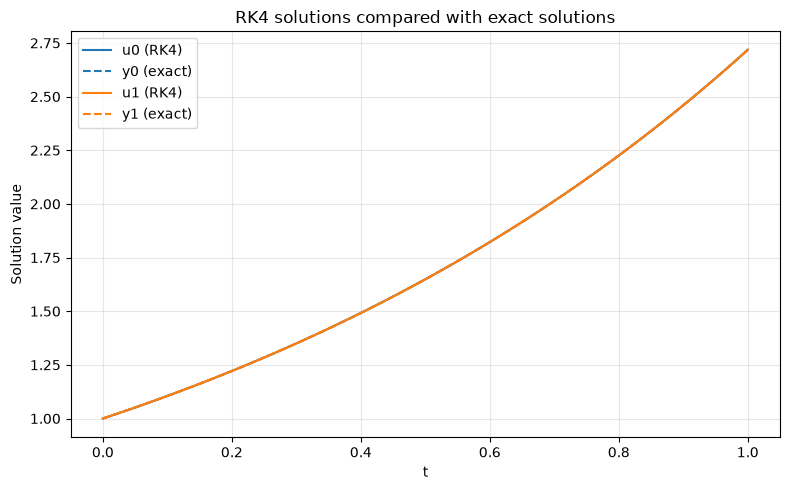

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(t, u0, label="u0 (RK4)", color="tab:blue")
ax.plot(t, y0, "--", label="y0 (exact)", color="tab:blue")
ax.plot(t, u1, label="u1 (RK4)", color="tab:orange")
ax.plot(t, y1, "--", label="y1 (exact)", color="tab:orange")

ax.set_xlabel("t")
ax.set_ylabel("Solution value")
ax.set_title("RK4 solutions compared with exact solutions")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [10]:
evaluator = objects.Evaluator(ivp=test_ivp,solver=objects.RK4)

In [11]:
t, absolute_error = evaluator.errvstime(N = N)

Text(0.5, 1.0, 'RK4 absolute error for $N=100$ ')

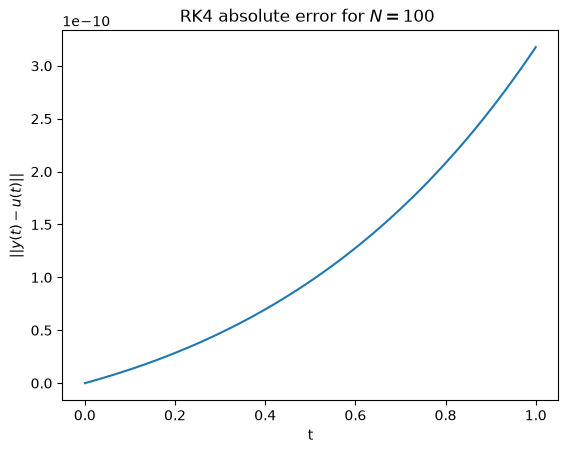

In [12]:
plt.plot(t,absolute_error)
plt.xlabel("t")
plt.ylabel(r"$||y(t)-u(t)||$")
plt.title(f"RK4 absolute error for $N={N}$ ")

In [13]:
step_size, final_error = evaluator.errvsh([N,N*2,N*3,N*5,N*8,N*10])

In [14]:
p = np.round((np.log(final_error[-1])-np.log(final_error[0]))/(np.log(step_size[-1])-np.log(step_size[-0])),4)

Text(0.5, 0, '$log(\\Delta t)$')

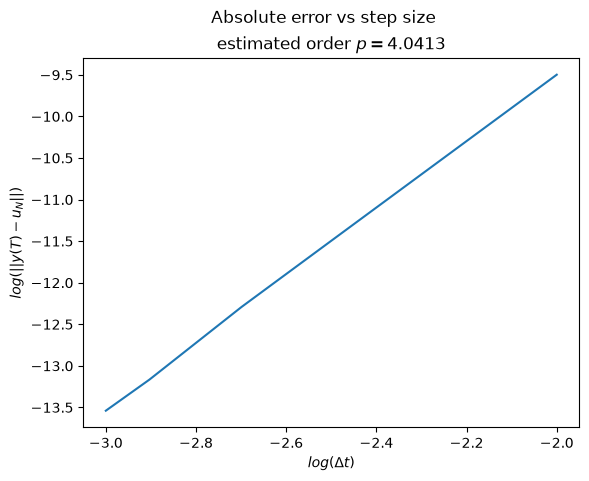

In [16]:
plt.plot(np.log10(step_size),np.log10(final_error))
plt.title(rf"estimated order $p={p}$")
plt.suptitle("Absolute error vs step size")
plt.ylabel(r"$log(||y(T)-u_N||)$")
plt.xlabel(r"$log(\Delta t)$")